### Problem 3 : SVMs & Random Forests - forgetting by locality

⏱️ ~30 min · 🧭 Stage 1 (Classical ML), rung 3 · 📄 `resources/papers/02-exact-unlearning/` (DaRE, HedgeCut)

> 🔗 **Building on Problem 2 :** the Newton step needed three things - a gradient, an invertible Hessian, and a single
> optimum. Now we take the gradient away entirely. A decision tree is built by greedy `if/else` splits; there is no
> slope to follow and no curvature to invert.

So how can a model with no calculus forget anything cheaply ? The answer is a new property, and it is the most useful
one in this whole course : **locality**.

> **Locality** : if you know *which part* of a model a data point influenced, you only need to rebuild that part.

We look at two flavours of it :

| Model | Where the locality comes from | What forgetting costs |
|---|---|---|
| **SVM** | the decision boundary depends only on the *support vectors* - most training points have **zero** influence | nothing at all, unless you delete a support vector |
| **Random forest** | each tree only saw its own *bag* of rows | retrain only the trees whose bag contained the row |

**TASK :** Make an SVM and a random forest forget Carol, find out *when* forgetting is free and when it is not, and
design a forest that forgets Carol by retraining only a fifth of it.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.datasets import make_blobs
from mul import lab, classical, viz
viz.style()

L = lab.make_lab("carol")
acc = lambda m, X, y: float((m.predict(X) == y).mean())
print(L)

Lab('carol': |D|=1257, |D_f|=40, |D_r|=1217, |test|=540)


----
### Part A : Support Vector Machines - most of the data does not matter

> 🟢 **In plain words :** an SVM draws the widest possible "street" between two classes. Only the points standing on the
> kerb of that street - the **support vectors** - decide where it goes. Every point further away could vanish and the
> street would not move an inch. So deleting one of *those* points is already unlearned, for free.

> 🔴 **For practitioners :** in the dual, the decision function is `f(x) = Σᵢ αᵢyᵢK(xᵢ, x) + b` with `αᵢ = 0` for every
> non-support vector. Removing a point with `αᵢ = 0` leaves the KKT conditions of the remaining problem satisfied, so the
> optimum is unchanged. Removing a support vector requires re-solving - incrementally if you like (Cauwenberghs & Poggio's
> *decremental* SVM, NIPS 2000) - but only because that point actually mattered.

#### Step 1 : Train - on a 2-D toy problem first, so we can *see* it

In [2]:
# Step 1: two overlapping clouds, a linear SVM
Xs, ys = make_blobs(200, centers=2, cluster_std=1.6, random_state=4)
svm = SVC(kernel="linear", C=1.0, tol=1e-6).fit(Xs, ys)
sv = svm.support_
non_sv = np.setdiff1d(np.arange(len(Xs)), sv)
print(f"{len(sv)} of {len(Xs)} points are support vectors ({len(sv)/len(Xs):.0%}); the other {len(non_sv)} have zero influence.")

54 of 200 points are support vectors (27%); the other 146 have zero influence.


#### Step 2, 3, 4 : Delete a non-support vector, then a support vector, and watch the boundary

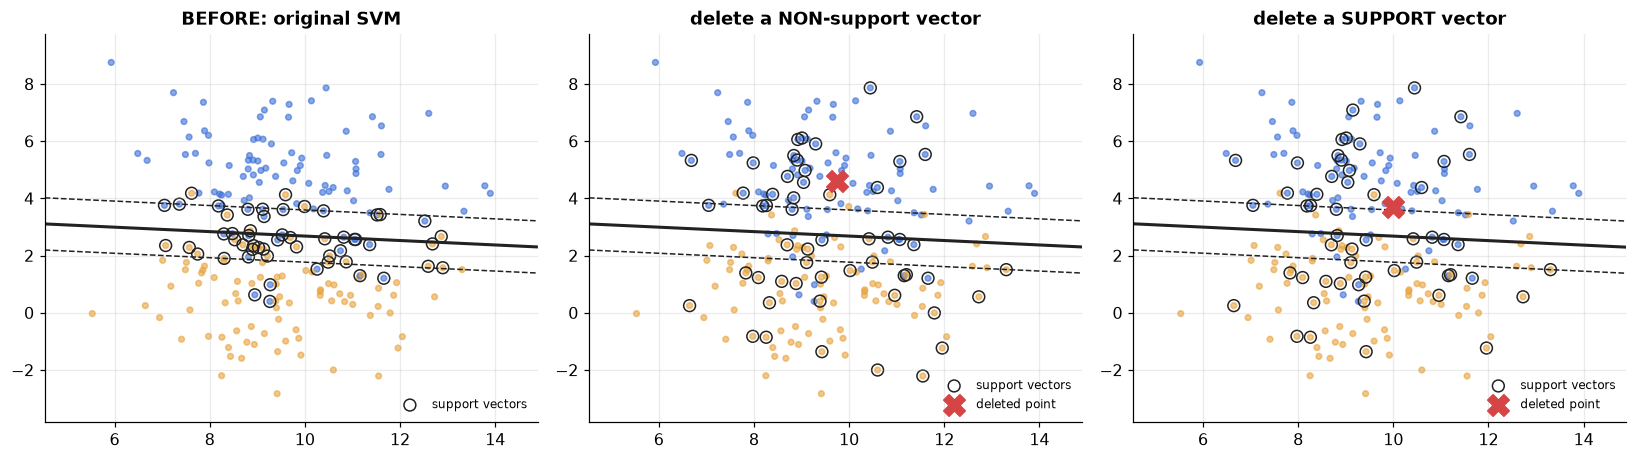

delete a non-SV: largest change in the boundary weights = 2.3e-08
delete a SV    : largest change in the boundary weights = 1.1e-03


In [3]:
def boundary(ax, model, X, y, title, removed=None):
    xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - 1, X[:, 0].max() + 1, 200), np.linspace(X[:, 1].min() - 1, X[:, 1].max() + 1, 200))
    Z = model.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contour(xx, yy, Z, levels=[-1, 0, 1], colors=[viz.INK], linestyles=["--", "-", "--"], linewidths=[1, 2, 1])
    ax.scatter(X[:, 0], X[:, 1], c=[viz.RETAIN if t else viz.ACCENT for t in y], s=14, alpha=0.6)
    ax.scatter(*X[model.support_].T, s=60, facecolors="none", edgecolors=viz.INK, lw=1, label="support vectors")
    if removed is not None:
        ax.scatter(*removed, marker="X", s=200, c=viz.FORGET, label="deleted point", zorder=5)
    ax.set_title(title); ax.legend(loc="lower right", fontsize=8)

victim_non, victim_sv = non_sv[0], sv[np.argmax(np.abs(svm.dual_coef_[0]))]
fits = {}
for name, v in [("non-SV", victim_non), ("SV", victim_sv)]:
    keep = np.setdiff1d(np.arange(len(Xs)), [v])
    fits[name] = SVC(kernel="linear", C=1.0, tol=1e-6).fit(Xs[keep], ys[keep])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
boundary(axes[0], svm, Xs, ys, "BEFORE: original SVM")
boundary(axes[1], fits["non-SV"], Xs, ys, "delete a NON-support vector", Xs[victim_non])
boundary(axes[2], fits["SV"], Xs, ys, "delete a SUPPORT vector", Xs[victim_sv])
plt.tight_layout(); plt.show()

for name in fits:
    d = np.abs(fits[name].coef_ - svm.coef_).max()
    print(f"delete a {name:6s}: largest change in the boundary weights = {d:.1e}")

Deleting the non-support vector changes the boundary by ~1e-8 - the solver's tolerance, i.e. **nothing**. Deleting a
support vector visibly moves it. So for an SVM, "do I need to do any work to forget this point ?" has an exact answer :
**only if it is a support vector.**

#### Now the real lab : is Carol a support vector ?

In [4]:
# Step 1 (lab): an RBF-kernel SVM on all ten digits
svc = SVC(kernel="rbf", C=10, gamma="scale").fit(L.X_train, L.y_train)
is_sv = np.zeros(len(L.X_train), bool); is_sv[svc.support_] = True

print(f"support vectors among Carol's digits : {is_sv[L.forget_idx].mean():6.1%}")
print(f"support vectors among everyone else  : {is_sv[L.retain_idx].mean():6.1%}")

support vectors among Carol's digits :  97.5%
support vectors among everyone else  :  40.5%


**Read that again.** Almost *every one* of Carol's digits is a support vector, versus well under half of everyone
else's. This is the same story as leverage in Problem 2, told by a different model : **atypical data is exactly the data
a model leans on** - and therefore exactly the data that is expensive to forget. Deleting a typical user is often free;
deleting Carol is not.

In [5]:
# Step 2: the issue - the SVM memorised her
svc_never = SVC(kernel="rbf", C=10, gamma="scale").fit(L.Xr, L.yr)      # gold standard
print(f"{'':28s}{'original':>10s}{'never saw Carol':>17s}")
for name, X, y in [("accuracy on Carol (D_f)", L.Xf, L.yf), ("accuracy on unseen thick", L.X_like_forget, L.y_like_forget),
                   ("accuracy on test", L.X_test, L.y_test)]:
    print(f"{name:28s}{acc(svc, X, y):10.1%}{acc(svc_never, X, y):17.1%}")

                              original  never saw Carol
accuracy on Carol (D_f)         100.0%            57.5%
accuracy on unseen thick         87.5%            48.8%
accuracy on test                 99.4%            99.4%


In [6]:
# Step 3 + 5: forgetting 40 TYPICAL non-support-vector users is free - prove it
typical = np.where(~is_sv)[0][:40]
keep = np.setdiff1d(np.arange(len(L.X_train)), typical)
svc_typical_removed = SVC(kernel="rbf", C=10, gamma="scale").fit(L.X_train[keep], L.y_train[keep])
X_all = np.r_[L.X_train, L.X_test, L.X_like_forget]
print(f"40 non-SV users deleted -> predictions identical to the original on {np.mean(svc_typical_removed.predict(X_all) == svc.predict(X_all)):.1%} of inputs")
print("=> for them, the original model already IS the unlearned model. Zero work.")

40 non-SV users deleted -> predictions identical to the original on 100.0% of inputs
=> for them, the original model already IS the unlearned model. Zero work.


For Carol, we have no such luck : 39 of her 40 digits are support vectors, so the only exact option is to re-solve the
SVM without her (`svc_never` above, a fraction of a second here, but O(n²)-O(n³) for kernel SVMs at scale).

----
### Part B : Random forests - retrain only the trees that saw the row

> 🟢 **In plain words :** a random forest is a committee of decision trees, and each tree is trained on its own random
> "bag" of rows. If Carol's digit was never in tree #7's bag, tree #7 has never seen her - we can leave it alone. We only
> rebuild the trees that met her.

> 🔴 **For practitioners :** this is exact as long as each retrained tree uses the same random state and the same bag
> minus the deleted rows - every untouched tree is then bit-identical to a from-scratch fit. DaRE forests (Brophy & Lowd
> 2021) go further and retrain only the affected *subtrees*, using cached split statistics; HedgeCut (Schelter et al.
> 2021) keeps alternative subtrees ready for low-latency deletion. Both are in `resources/papers/02-exact-unlearning/`.

#### Step 1 : Train a classic forest (bootstrap bags)

In [7]:
# Step 1: 50 trees, each on a bootstrap sample of the whole training set
forest = classical.BaggedForest(n_trees=50, seed=0).fit(L.X_train, L.y_train)
forest_never = classical.BaggedForest(n_trees=50, seed=0).fit(L.Xr, L.yr)          # (a gold standard)
print(f"{'':28s}{'original':>10s}{'never saw Carol':>17s}")
for name, X, y in [("accuracy on Carol (D_f)", L.Xf, L.yf), ("accuracy on unseen thick", L.X_like_forget, L.y_like_forget),
                   ("accuracy on test", L.X_test, L.y_test)]:
    print(f"{name:28s}{acc(forest, X, y):10.1%}{acc(forest_never, X, y):17.1%}")

                              original  never saw Carol
accuracy on Carol (D_f)         100.0%            30.0%
accuracy on unseen thick         70.0%            48.8%
accuracy on test                 97.2%            97.2%


#### Step 2 : Show the issue - how *local* is a classic forest, really ?

In [8]:
# Step 2: how many trees did each training row touch ?
touches = np.zeros(len(L.X_train), int)
for bag in forest.bags:
    touches[np.unique(bag)] += 1
print(f"a typical row appears in {touches.mean():.1f} of 50 trees ({touches.mean()/50:.0%})")
print(f"Carol's 40 rows together appear in {sum(np.isin(b, L.forget_idx).any() for b in forest.bags)} of 50 trees")

a typical row appears in 31.6 of 50 trees (63%)
Carol's 40 rows together appear in 50 of 50 trees


That is the catch. A bootstrap bag draws `n` rows *with replacement* from `n`, so any given row lands in about
`1 − (1 − 1/n)ⁿ ≈ 63%` of the trees. One deletion already means rebuilding two-thirds of the forest, and Carol's 40 rows
reach **every single tree**. The locality is there in principle - but a classic forest is not *designed* for it.

#### Step 3 : Untrain - and redesign the forest for deletion

We compare three designs, all with 50 trees :

1. **Bootstrap** - the classic forest above.
2. **Random shards** - split the data into 5 disjoint shards; 10 trees per shard, each bootstrapping only from its own
   shard. A row now lives in exactly one shard.
3. **User-aware shards** - the same, but **all of one user's data goes into the same shard**. Carol is a single shard.

In [9]:
# Step 3: build the three designs and unlearn Carol from each
def shard_bags(shards, trees_per_shard=10, seed=0):
    rng = np.random.default_rng(seed)
    return [rng.choice(sh, len(sh), replace=True) for sh in shards for _ in range(trees_per_shard)]

perm = np.random.default_rng(0).permutation(len(L.X_train))
random_shards = np.array_split(perm, 5)
others = perm[~np.isin(perm, L.forget_idx)]
user_shards = np.array_split(others, 5)
user_shards[0] = np.r_[user_shards[0], L.forget_idx]                     # Carol lives in shard 0 only

designs = {"bootstrap": None, "random shards": shard_bags(random_shards), "user-aware shards": shard_bags(user_shards)}
results = {}
for name, bags in designs.items():
    f = classical.BaggedForest(n_trees=50, seed=0).fit(L.X_train, L.y_train, bags=bags)
    before = (acc(f, L.Xf, L.yf), acc(f, L.X_test, L.y_test))
    one = classical.BaggedForest(n_trees=50, seed=0).fit(L.X_train, L.y_train, bags=bags).unlearn([L.retain_idx[5]])
    info = f.unlearn(L.forget_idx)
    results[name] = dict(test_before=before[1], carol_before=before[0], carol_after=acc(f, L.Xf, L.yf),
                         test_after=acc(f, L.X_test, L.y_test), one_row=one["trees_retrained"], carol=info["trees_retrained"], model=f)

#### Step 4 : Show the result

design                test acc  Carol before  Carol after                  trees to retrain
                                                            (1 random row)          (Carol)
bootstrap                97.2%        100.0%        40.0%          31 / 50          50 / 50
random shards            94.4%         90.0%        42.5%           8 / 50          49 / 50
user-aware shards        94.4%         95.0%        42.5%           9 / 50          10 / 50


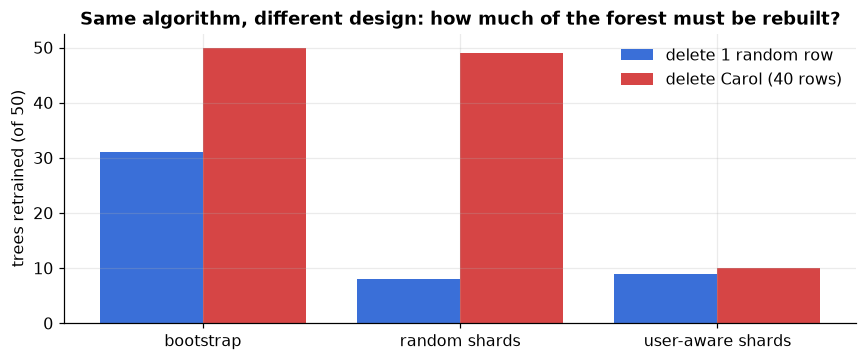

In [10]:
print(f"{'design':20s}{'test acc':>10s}{'Carol before':>14s}{'Carol after':>13s}{'trees to retrain':>34s}")
print(f"{'':20s}{'':10s}{'':14s}{'':13s}{'(1 random row)':>17s}{'(Carol)':>17s}")
for name, r in results.items():
    print(f"{name:20s}{r['test_before']:10.1%}{r['carol_before']:14.1%}{r['carol_after']:13.1%}{r['one_row']:>12d} / 50{r['carol']:>12d} / 50")

fig, ax = plt.subplots(figsize=(8, 3.4))
x = np.arange(3)
ax.bar(x - 0.2, [r["one_row"] for r in results.values()], 0.4, color=viz.RETAIN, label="delete 1 random row")
ax.bar(x + 0.2, [r["carol"] for r in results.values()], 0.4, color=viz.FORGET, label="delete Carol (40 rows)")
ax.set_xticks(x); ax.set_xticklabels(results.keys()); ax.set_ylabel("trees retrained (of 50)"); ax.legend()
ax.set_title("Same algorithm, different design: how much of the forest must be rebuilt?"); plt.tight_layout(); plt.show()

#### Step 5 : Prove it - the user-aware forest is exactly a forest that never saw Carol

In [11]:
f_user = results["user-aware shards"]["model"]
f_scratch = classical.BaggedForest(n_trees=50, seed=0).fit(L.X_train, L.y_train, bags=[b.copy() for b in f_user.bags])
print(f"max difference in predicted probabilities vs a from-scratch fit without Carol: "
      f"{np.abs(f_user.predict_proba(X_all) - f_scratch.predict_proba(X_all)).max():.1e}")

max difference in predicted probabilities vs a from-scratch fit without Carol: 0.0e+00


✅ **Exact**, and Carol cost 10 trees instead of 50.

> ⚠️ Notice the price in the table : the sharded forests are a few points **less accurate**, because each tree only
> sees a fifth of the data. That is the fundamental trade-off of designing for deletion - you pay a little accuracy
> *every day* so that forgetting is cheap *on the day someone asks*. Problem 7 meets exactly the same trade-off in
> neural networks, under the name **SISA**.

----
#### OUTCOME :

| Model | Locality | Forgetting a typical user | Forgetting Carol |
|---|---|---|---|
| SVM | only support vectors matter | **free** (non-SVs have zero influence) | re-solve - she is almost all support vectors |
| Forest, bootstrap | each tree has a bag, but bags overlap heavily | ~60% of trees | **all** trees |
| Forest, user-aware shards | each user lives in one shard | 1 shard | **1 shard** (10 of 50 trees) |

Two lessons carry forward :

1. **Influence is not spread evenly.** Atypical data (Carol) is what models lean on - more support vectors, more
   leverage, more memorisation. That data is the expensive data to forget, and it is usually the data people ask about.
2. **Locality can be *designed in*.** Whether forgetting costs 10 trees or 50 was decided at *training* time, by how we
   partitioned the data. Shard by the unit people will ask to delete (a user, a customer, a document source).

#### Key Takeaways :

- An SVM depends only on its support vectors; deleting anything else is **already** unlearned.
- Forests forget **exactly** by retraining only the trees whose bags contained the row.
- Bootstrap bags destroy locality (~63% of trees per row). Disjoint, **user-aware shards** restore it.
- Designing for deletion costs a little accuracy up front - the core trade-off of exact unlearning.

#### TASK :
1. Change the number of shards from 5 to 2 and to 10. Plot test accuracy against "trees retrained for Carol". Where
   would you set it for a service that receives 1,000 deletion requests a day?
2. Replace the bootstrap bags inside each shard with bags *without* replacement (`replace=False`). How do accuracy and
   locality change?
3. For the RBF SVM, find the typical user whose deletion moves the decision function the *most* while not being a
   support vector. (Trick question - what does the theory predict ?)
4. Read the DaRE paper's Section 3 (`resources/papers/02-exact-unlearning/2020-brophy-dare-random-forests.pdf`). How do
   cached split statistics let DaRE retrain a *subtree* instead of a whole tree?

#### ❓ Open question → Problem 4
Every model so far had something we could exploit : sums (1), a closed form or a convex optimum (2), or locality (3).
**A neural network has none of them.** Every training example nudges every weight, the loss is not convex, and there is
no formula for the answer. What happens to Carol inside a neural network - and do any of our tricks survive ?